In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
from timeit import default_timer as timer

2. **Load the Dataset**

In [ ]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

print(f"Training samples: {len(train_data)}")
print(f"Testing samples: {len(test_data)}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]

100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]

100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 2.60MB/s]

Training samples: 60000
Testing samples: 10000
Training samples: 60000
Testing samples: 10000


3. **Create DataLoaders** - This cell wraps the datasets in DataLoaders to manage the 32 image batches and shuffling.

In [ ]:
BATCH_SIZE = 32

train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoaders created with batch size: {BATCH_SIZE}")

DataLoaders created with batch size: 32


**4: The Sanity Check**

In [ ]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))

print(f"Image tensor shape: {train_features_batch.shape} -> [batch, color_channels, height, width]")
print(f"Label tensor shape: {train_labels_batch.shape}")

Image tensor shape: torch.Size([32, 1, 28, 28]) -> [batch, color_channels, height, width]
Label tensor shape: torch.Size([32])
Image tensor shape: torch.Size([32, 1, 28, 28]) -> [batch, color_channels, height, width]
Label tensor shape: torch.Size([32])


In [ ]:
from torch import nn


class FashionBaseline(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()


        self.linear_layers = nn.Sequential(
            nn.Linear(in_features=784, out_features=128),
            nn.ReLU(),
            nn.Linear(in_features=128, out_features=10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.linear_layers(x)


torch.manual_seed(42)
model_0 = FashionBaseline()

print(model_0)

FashionBaseline(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
FashionBaseline(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_0.parameters(), lr=0.1)


epochs = 3

for epoch in range(epochs):
    print(f"Epoch: {epoch+1}\n-------")
    train_loss = 0


    for batch, (X, y) in enumerate(train_dataloader):
        y_pred = model_0(X)


        loss = loss_fn(y_pred, y)
        train_loss += loss


        optimizer.zero_grad()


        loss.backward()


        optimizer.step()


        if batch % 400 == 0:
            print(f"Processed {batch * len(X)}/{len(train_dataloader.dataset)} samples. Current Loss: {loss.item():.4f}")


    train_loss /= len(train_dataloader)
    print(f"Average Train Loss for Epoch {epoch+1}: {train_loss:.4f}\n")

Epoch: 1
-------
Epoch: 1
-------
Processed 0/60000 samples. Current Loss: 2.3020
Processed 0/60000 samples. Current Loss: 2.3020
Processed 12800/60000 samples. Current Loss: 0.6880
Processed 12800/60000 samples. Current Loss: 0.6880
Processed 25600/60000 samples. Current Loss: 0.5566
Processed 25600/60000 samples. Current Loss: 0.5566
Processed 38400/60000 samples. Current Loss: 0.7275
Processed 38400/60000 samples. Current Loss: 0.7275
Processed 51200/60000 samples. Current Loss: 0.6052
Processed 51200/60000 samples. Current Loss: 0.6052
Average Train Loss for Epoch 1: 0.5635

Epoch: 2
-------
Processed 0/60000 samples. Current Loss: 0.6233
Average Train Loss for Epoch 1: 0.5635

Epoch: 2
-------
Processed 0/60000 samples. Current Loss: 0.6233
Processed 12800/60000 samples. Current Loss: 0.4722
Processed 12800/60000 samples. Current Loss: 0.4722
Processed 25600/60000 samples. Current Loss: 0.3680
Processed 25600/60000 samples. Current Loss: 0.3680
Processed 38400/60000 samples. Curre

In [ ]:

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

test_loss, test_acc = 0, 0
model_0.eval()

with torch.inference_mode():
    for X, y in test_dataloader:

        test_pred = model_0(X)


        test_loss += loss_fn(test_pred, y)


        test_pred_labels = test_pred.argmax(dim=1)


        test_acc += accuracy_fn(y_true=y, y_pred=test_pred_labels)


    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

print(f"Baseline Model -> Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%")

Baseline Model -> Test Loss: 0.3774 | Test Accuracy: 86.39%


**The CNN**

In [ ]:
class FashionCNN(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()


        self.block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )


        self.block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )


        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(in_features=hidden_units * 7 * 7, out_features=output_shape)
        )

    def forward(self, x):
        x = self.block_1(x)
        x = self.block_2(x)
        x = self.classifier(x)
        return x


torch.manual_seed(42)
model_1 = FashionCNN(
    input_shape=1,
    hidden_units=10,
    output_shape=10
)

print(model_1)

FashionCNN(
  (block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)


**CNN Training loop**


In [ ]:

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Training on device: {device}")


model_1.to(device)


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.1)


epochs = 3

for epoch in range(epochs):
    print(f"Epoch: {epoch+1}\n-------")
    train_loss = 0
    model_1.train()

    for batch, (X, y) in enumerate(train_dataloader):

        X, y = X.to(device), y.to(device)

        y_pred = model_1(X)

        loss = loss_fn(y_pred, y)
        train_loss += loss


        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % 400 == 0:
            print(f"Processed {batch * len(X)}/{len(train_dataloader.dataset)} samples. Current Loss: {loss.item():.4f}")

    train_loss /= len(train_dataloader)
    print(f"Average Train Loss for Epoch {epoch+1}: {train_loss:.4f}\n")

Training on device: cuda
Epoch: 1
-------
Processed 0/60000 samples. Current Loss: 2.3102
Processed 12800/60000 samples. Current Loss: 0.3384
Processed 25600/60000 samples. Current Loss: 0.5418
Processed 38400/60000 samples. Current Loss: 0.4261
Processed 51200/60000 samples. Current Loss: 0.2420
Average Train Loss for Epoch 1: 0.5780

Epoch: 2
-------
Processed 0/60000 samples. Current Loss: 0.3012
Processed 12800/60000 samples. Current Loss: 0.2140
Processed 25600/60000 samples. Current Loss: 0.2252
Processed 38400/60000 samples. Current Loss: 0.2773
Processed 51200/60000 samples. Current Loss: 0.1627
Average Train Loss for Epoch 2: 0.3576

Epoch: 3
-------
Processed 0/60000 samples. Current Loss: 0.2841
Processed 12800/60000 samples. Current Loss: 0.1367
Processed 25600/60000 samples. Current Loss: 0.4368
Processed 38400/60000 samples. Current Loss: 0.2463
Processed 51200/60000 samples. Current Loss: 0.5213
Average Train Loss for Epoch 3: 0.3191



**Test Acurracy**

In [ ]:
test_loss_cnn, test_acc_cnn = 0, 0
model_1.eval()

with torch.inference_mode():
    for X, y in test_dataloader:

        X, y = X.to(device), y.to(device)


        test_pred = model_1(X)
        test_loss_cnn += loss_fn(test_pred, y)


        test_pred_labels = test_pred.argmax(dim=1)
        test_acc_cnn += accuracy_fn(y_true=y, y_pred=test_pred_labels)


    test_loss_cnn /= len(test_dataloader)
    test_acc_cnn /= len(test_dataloader)

print(f"CNN Model -> Test Loss: {test_loss_cnn:.4f} | Test Accuracy: {test_acc_cnn:.2f}%")

CNN Model -> Test Loss: 0.3473 | Test Accuracy: 87.44%


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 23.9 MB/s eta 0:00:00


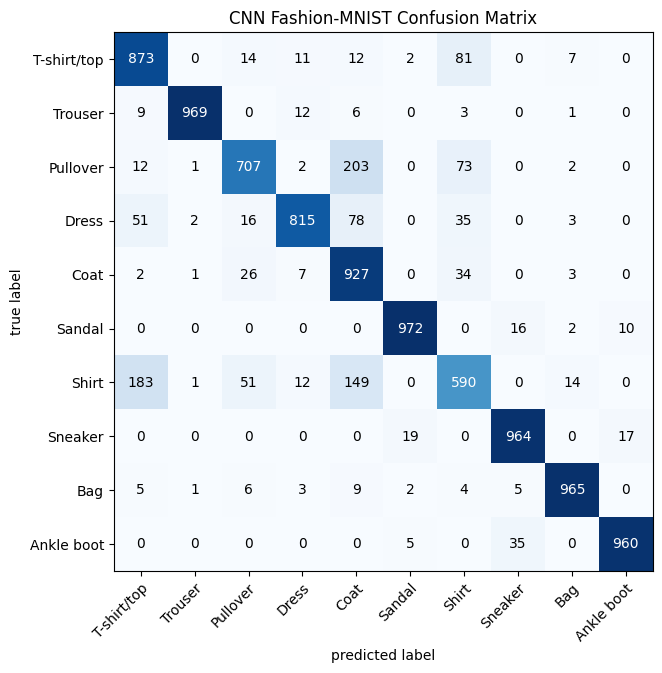

In [ ]:

#pip install -q torchmetrics mlxtend

import torch
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
import matplotlib.pyplot as plt

y_preds = []
model_1.eval()
with torch.inference_mode():
    for X, y in test_dataloader:
        X, y = X.to(device), y.to(device)


        y_logit = model_1(X)
        y_pred = torch.softmax(y_logit, dim=1).argmax(dim=1)


        y_preds.append(y_pred.cpu())


y_pred_tensor = torch.cat(y_preds)


confmat = ConfusionMatrix(num_classes=10, task='multiclass')
confmat_tensor = confmat(preds=y_pred_tensor, target=test_data.targets)


fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=test_data.classes,
    figsize=(10, 7)
)
plt.title("CNN Fashion-MNIST Confusion Matrix")
plt.show()

GradCAM

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


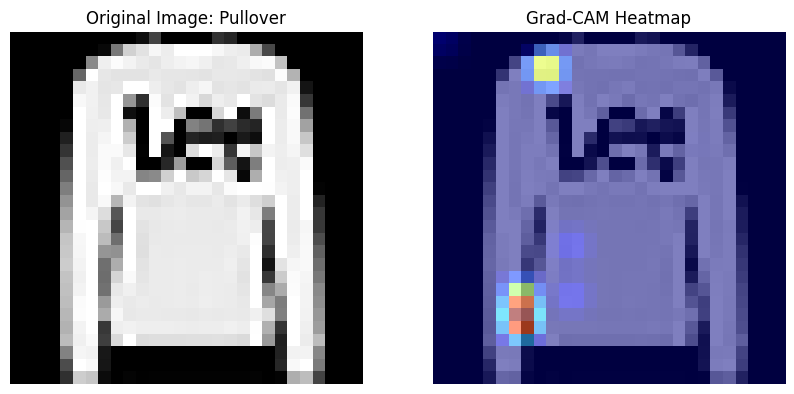

In [ ]:

#pip install -q grad-cam

import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


target_image, target_label = test_data[1]
input_tensor = target_image.unsqueeze(0).to(device)


target_layers = [model_1.block_2[2]]


cam = GradCAM(model=model_1, target_layers=target_layers)


targets = [ClassifierOutputTarget(target_label)]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
grayscale_cam = grayscale_cam[0, :]


img_rgb = target_image.permute(1, 2, 0).numpy()
img_rgb = np.repeat(img_rgb, 3, axis=2)

visualization = show_cam_on_image(img_rgb, grayscale_cam, use_rgb=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))


ax1.imshow(target_image.squeeze(), cmap='gray')
ax1.set_title(f"Original Image: {test_data.classes[target_label]}")
ax1.axis('off')


ax2.imshow(visualization)
ax2.set_title("Grad-CAM Heatmap")
ax2.axis('off')

plt.show()

In [ ]:
from pathlib import Path


MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)


MODEL_NAME = "fashion_cnn_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME


print(f"Saving model weights to: {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(), f=MODEL_SAVE_PATH)

Saving model weights to: models/fashion_cnn_model.pth
